# Linear model: performance on the eval year

An analysis of the linear model (`models.linear_model`, `docs/linear_model.md`) on the held-out
eval year, 2025-10-20 → 2026-10-20: 1,448 forecast runs, one every 6 hours, each 72 hours long.
The model was selected and fitted on the training years only. The eval year was scored once by
`python -m training.linear_model evaluate`; this notebook breaks that score down. Nothing here
feeds back into the model's choices.

The model is a per-lead Gaussian GLM on the target **speed − last observed speed** (relative to
persistence, no Box-Cox transform), weighted by each run's TIMSE weights. Its inputs are the
final baseline's speed terms (last speed, 27-day and 13.5-day recurrence) plus five regressors:

| Regressor | What it is |
|---|---|
| `ch_cm_at_12h` | coronal-hole area in the central-meridian strip, AIA 193 image 12 h before t0 |
| `density_mean_24h` | proton density, mean of the last 24 h |
| `xray_peak_max_48h` | log peak X-ray flare flux in the last 48 h |
| `b_var_mean_48h` | field variability, mean of the last 48 h |
| `f107_mean_168h` | F10.7 radio flux, mean of the last 7 days |

It is compared against the **final baseline** (the reference model and current submission) and
**persistence**.

1. **Scores:** overall, and how the per-run distribution changes.
2. **By regime:** the run labels of `final_baseline_analysis.ipynb` (CME, stream arrival, quiet wind…).
3. **Bias and level:** does the regression fix the baseline's over-forecast of quiet wind?
4. **Stream arrivals:** does the coronal-hole regressor give arrival timing?
5. **The regressors:** coefficients, contributions, ablation, and the coronal-hole archive gap.
6. **Through the year and the worst runs.**
7. **Findings.**

**Conventions:**
- **Residual** = actual − forecast; negative means the model over-predicted.
- **Ratio** = a run's TIMSE for one model divided by another's for the same run. Below 1, the first model wins.
- **Per-run** scores treat each 72-hour run on its own, as the platform scores each submission.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from feature_engineering.recurrence import last_observed, targets
from models.final_baseline import FinalBaseline, run_timse_weights
from models.linear_model import LinearModel
from training import solar_wind_events as ev
from training.datasets import EVAL_END, TRAIN_END, load_hourly
from training.evaluate import HORIZON, forecast_times, run_timse
from training.linear_model import candidate_table
from training.metrics import timse

plt.rcParams.update(
    {"figure.figsize": (11, 3.5), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3}
)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

MODELS = ["linear_model", "final_baseline", "persistence"]
STYLE = {
    "linear_model": {"color": "#eb6834", "lw": 1.8},
    "final_baseline": {"color": "#2a78d6", "lw": 1.5},
    "persistence": {"color": "#8a8984", "lw": 1.5, "ls": (0, (1, 1.5))},
}
REGIME_COLORS = {
    "CME": "#e34948", "possible CME": "#e87ba4", "stream arrival": "#eda100",
    "fast stream": "#6250d6", "slow wind": "#1baf7a", "intermediate": "#52514e",
}
CME_SPAN = {"color": "#e34948", "alpha": 0.18, "lw": 0}
POSSIBLE_SPAN = {"color": "#e87ba4", "alpha": 0.18, "lw": 0}
GAP_SPAN = {"color": "#6250d6", "alpha": 0.12, "lw": 0}
WIN, LOSE = "#1baf7a", "#6250d6"
lead = np.arange(1, HORIZON + 1)


def model_legend(fig, extra=(), models=MODELS):
    handles = [Line2D([], [], **STYLE[m]) for m in models]
    labels = list(models)
    for handle, label in extra:
        handles.append(handle)
        labels.append(label)
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0),
               ncol=len(handles), frameon=False, fontsize=9)


def fmt(table):
    return table.map(lambda x: f"{x:.3g}" if isinstance(x, float) else x)

## 1. Scores

The linear model is loaded from the shipped asset (fitted on the training years) and run
walk-forward over every eval `t0`. Its regressors are built from the pulled history
(`training.pull_features`) with the live availability rules, and missing ones take their
training medians, as live. The batch forecast is checked against the live `predict()` path on
one run.

In [2]:
series = load_hourly()
values = series.to_numpy()
t0s = forecast_times()
pos = series.index.get_indexer(t0s)
actual = targets(values, pos)

model = LinearModel.load()
FEATURES = list(model.config.features)
table = candidate_table(t0s)
x = table[FEATURES].to_numpy(dtype=float)
imputed = pd.DataFrame(np.isnan(x), index=t0s, columns=FEATURES)

forecasts = {
    "linear_model": model.forecast(values, pos, x),
    "final_baseline": FinalBaseline.load().forecast(values, pos),
    "persistence": np.repeat(last_observed(values, pos)[:, None], HORIZON, 1),
}
i = 700
assert np.allclose(model.predict(series.iloc[: pos[i]], dict(zip(FEATURES, x[i], strict=True))),
                   forecasts["linear_model"][i])

residuals = {m: actual - f for m, f in forecasts.items()}
run_scores = pd.DataFrame({m: run_timse(forecasts[m], actual) for m in MODELS}, index=t0s)
vs_base = run_scores["linear_model"] / run_scores["final_baseline"]
vs_pers = run_scores["linear_model"] / run_scores["persistence"]
base_vs_pers = run_scores["final_baseline"] / run_scores["persistence"]

overall = pd.DataFrame({
    m: {
        "pooled TIMSE": timse(actual, forecasts[m]),
        "per-run mean": run_scores[m].mean(),
        "per-run median": run_scores[m].median(),
        "per-run p90": run_scores[m].quantile(0.9),
        "RMSE": float(np.sqrt(np.nanmean(residuals[m] ** 2))),
        "beats persistence": (run_scores[m] < run_scores["persistence"]).mean(),
    }
    for m in MODELS
}).T
print(f"{len(t0s)} runs; linear beats the final baseline in {(vs_base < 1).mean():.0%} of runs")
print("regressors imputed (share of runs):", imputed.mean().round(3).to_dict())
fmt(overall)

1448 runs; linear beats the final baseline in 56% of runs
regressors imputed (share of runs): {'ch_cm_at_12h': 0.197, 'density_mean_24h': 0.005, 'xray_peak_max_48h': 0.0, 'b_var_mean_48h': 0.0, 'f107_mean_168h': 0.0}


,pooled TIMSE,per-run mean,per-run median,per-run p90,RMSE,beats persistence
linear_model,4.75e+07,2.44e+06,7.21e+05,4e+06,106,0.57
final_baseline,5.58e+07,2.59e+06,8.45e+05,3.21e+06,110,0.532
persistence,8.13e+07,5.57e+06,7.76e+05,1.38e+07,110,0


**The per-run distribution.** The per-run mean is what the platform's per-run scoring averages,
and it is set by the worst runs. The table compares the two models' per-run TIMSE at several
quantiles. The scatter puts every run's linear-model TIMSE against the final baseline's: below the
diagonal, the linear model wins.

,linear_model,final_baseline,linear / baseline
p10,2.21e+05,2.48e+05,0.891
p25,4.15e+05,4.39e+05,0.946
p50,7.21e+05,8.45e+05,0.854
p75,1.48e+06,1.64e+06,0.904
p90,4e+06,3.21e+06,1.25
p95,7.5e+06,7.99e+06,0.938
p99,3.45e+07,4.67e+07,0.739


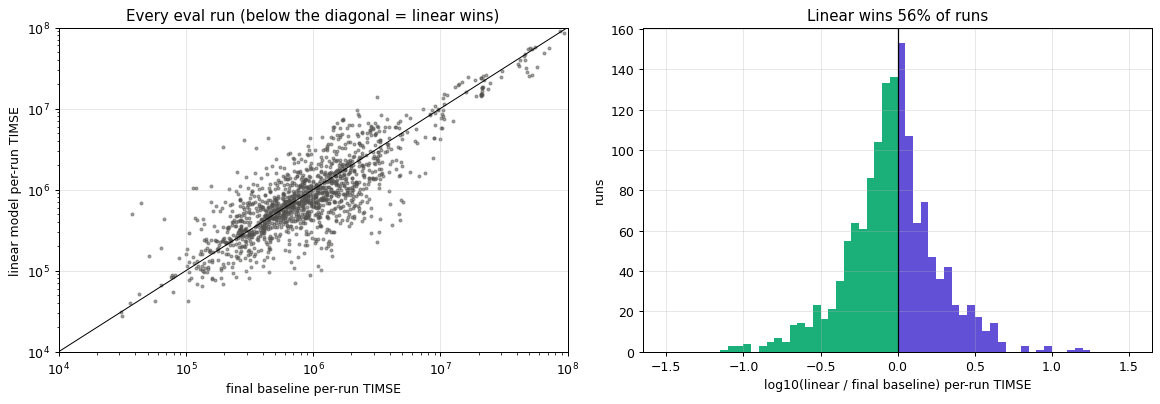

In [3]:
qs = [0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
quant = pd.DataFrame({m: run_scores[m].quantile(qs) for m in MODELS[:2]})
quant["linear / baseline"] = quant["linear_model"] / quant["final_baseline"]
quant.index = [f"p{int(q * 100)}" for q in qs]
display(fmt(quant))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
lo, hi = 1e4, 1e8
ax.plot([lo, hi], [lo, hi], color="k", lw=0.8)
ax.scatter(run_scores["final_baseline"], run_scores["linear_model"], s=5, alpha=0.5,
           color="#52514e")
ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi),
       xlabel="final baseline per-run TIMSE", ylabel="linear model per-run TIMSE",
       title="Every eval run (below the diagonal = linear wins)")
ax = axes[1]
r = np.log10(vs_base.dropna())
bins = np.linspace(-1.5, 1.5, 61)
ax.hist(r[r < 0], bins=bins, color=WIN)
ax.hist(r[r >= 0], bins=bins, color=LOSE)
ax.axvline(0, color="k", lw=1)
ax.set(xlabel="log10(linear / final baseline) per-run TIMSE", ylabel="runs",
       title=f"Linear wins {(r < 0).mean():.0%} of runs")
fig.tight_layout()

**Forecasts along the year.** The observed speed against the forecasts, from the first eval
run and then one run every 3 days. Runs are 72 h long, so each forecast starts where the
previous one ends: the forecasts tile the year without overlapping. Dotted lines mark each
run's `t0`, where the forecast restarts from the latest observation. One row per quarter.

**The spiky bands** in some runs (mid-November, 5 February, early July) are the training-data artefact of
section 5.5. The forecast jumps at every sixth lead (32, 38, … 68 h), and the jump is
largest when a regressor is far from its mean. Those runs follow large flares (flare regressor about
2.4 standard deviations above its mean) or an unusually steady field.

121 non-overlapping runs, 2025-10-20 00Z to 2026-10-18 00Z
per-run mean TIMSE on these runs: {'linear_model': '1.89e+06', 'final_baseline': '2.17e+06', 'persistence': '4.4e+06'} | linear wins 56%


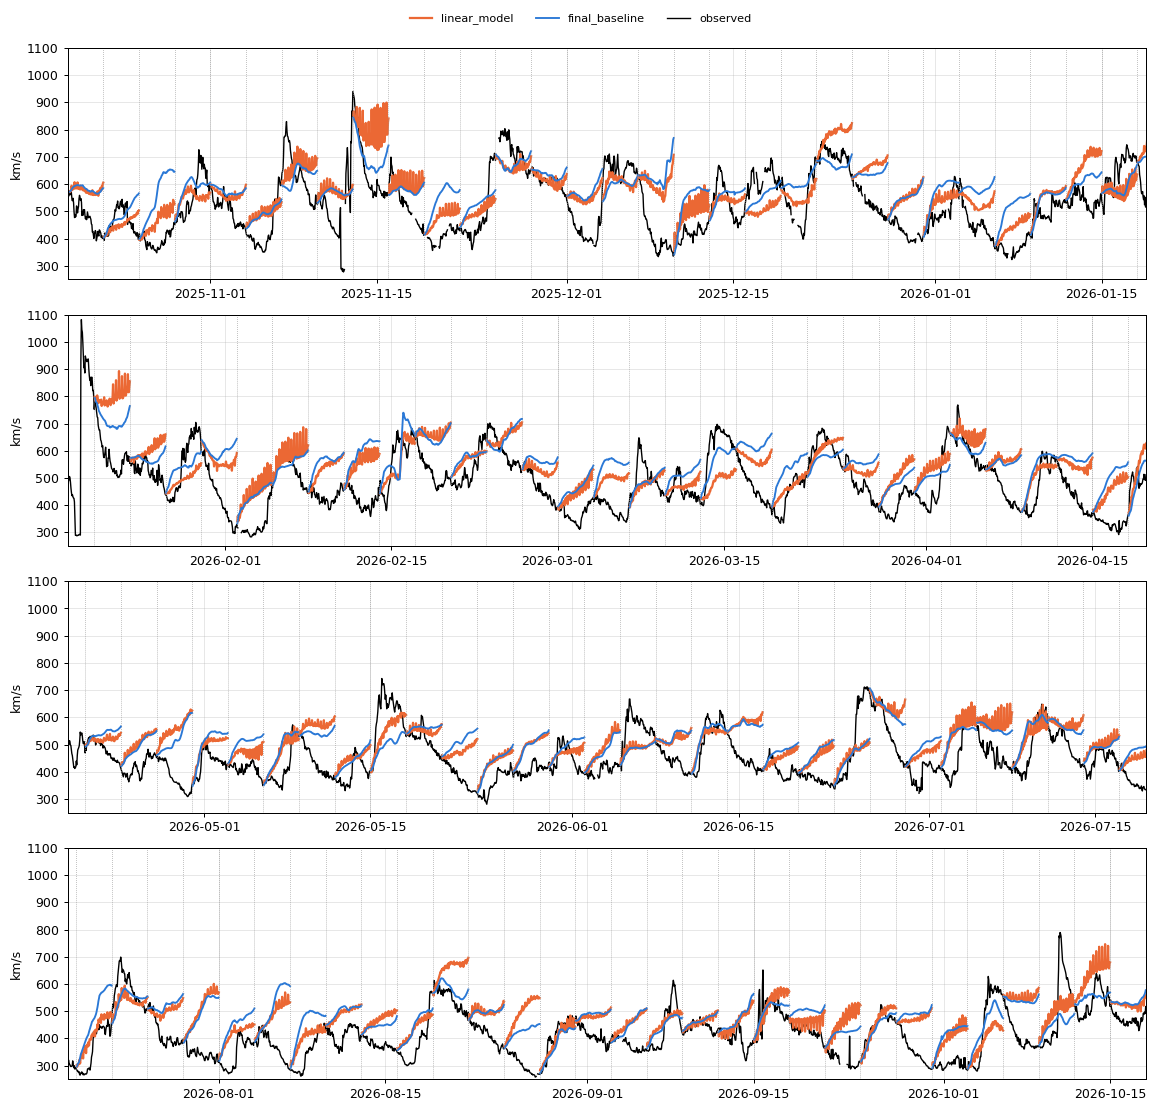

In [4]:
STRIDE = 72 // 6  # runs are 6-hourly; every 12th run is 3 days apart
tiled = np.arange(0, len(t0s), STRIDE)
tiled_times = [t0s[i] + pd.to_timedelta(lead, unit="h") for i in tiled]
valid_hours = tiled_times[0].append(tiled_times[1:])
# consecutive runs: no overlap and no gap
assert valid_hours.is_unique and (np.diff(valid_hours.asi8) == 3600 * 10**9).all()

tiled_scores = run_scores.iloc[tiled]
print(f"{len(tiled)} non-overlapping runs, {t0s[tiled[0]]:%Y-%m-%d %H}Z to "
      f"{t0s[tiled[-1]] + pd.Timedelta(hours=HORIZON):%Y-%m-%d %H}Z")
print("per-run mean TIMSE on these runs:",
      {m: f"{tiled_scores[m].mean():.3g}" for m in MODELS},
      f"| linear wins {(tiled_scores['linear_model'] < tiled_scores['final_baseline']).mean():.0%}")

quarters = pd.date_range(t0s[0], t0s[tiled[-1]] + pd.Timedelta(hours=HORIZON + 1), periods=5)
fig, axes = plt.subplots(4, 1, figsize=(13, 12))
for k, ax in enumerate(axes):
    lo, hi = quarters[k], quarters[k + 1]
    obs = series[lo:hi]
    ax.plot(obs.index, obs, color="k", lw=1.1)
    for r, i in enumerate(tiled):  # one line per run, so separate runs aren't joined
        if lo <= t0s[i] < hi:
            for m in MODELS[:2]:
                ax.plot(tiled_times[r], forecasts[m][i], **STYLE[m])
    for t in t0s[tiled][(t0s[tiled] >= lo) & (t0s[tiled] < hi)]:
        ax.axvline(t, color="0.6", lw=0.6, ls=":")
    ax.set(ylabel="km/s", xlim=(lo, hi), ylim=(250, 1100))
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=1.1), "observed")], models=MODELS[:2])

## 2. By regime

Each run is labelled by what happened during its 72 target hours (`ev.classify_runs`, as in
`final_baseline_analysis.ipynb`): CME, possible CME, stream arrival, fast stream, slow wind
(peak below 450 km/s), intermediate. The last four are the no-CME regimes.

For each regime:
- **runs** and their share of the year;
- **per-run mean** for both models, and the **change in the per-run total** it contributes (the regime's share of the overall change in the sum of per-run TIMSE: negative is a gain for the linear model);
- **median ratio** linear / baseline and how often the linear model wins;
- the median ratio of each model against persistence;
- **pooled TIMSE** of the linear model over the final baseline's, on the regime's runs.

In [5]:
cond_start = pd.Timestamp("2025-07-01T00:00Z")
minutes = ev.load_conditions(cond_start, EVAL_END)
hourly = minutes.resample("h").mean().reindex(
    pd.date_range(cond_start, EVAL_END, freq="h", inclusive="left", name="Time")
)
events = ev.detect_icmes(hourly, ev.detect_shocks(minutes))
cme = ev.cme_mask(hourly.index, events)
possible = ev.cme_mask(hourly.index, events, ("possible ICME",))
arrivals = ev.detect_stream_arrivals(hourly["speed"], cme | possible)
cme_hours = cme.reindex(series.index, fill_value=False)
possible_hours = possible.reindex(series.index, fill_value=False)
regime = pd.Series(ev.classify_runs(t0s, actual, cme_hours, arrivals, possible_hours),
                   index=t0s, name="regime")
no_cme = regime.isin(ev.NO_CME).to_numpy()

diff = run_scores["linear_model"] - run_scores["final_baseline"]
total_change = diff.sum()


def regime_row(sel):
    lin, base = run_scores.loc[sel, "linear_model"], run_scores.loc[sel, "final_baseline"]
    return {
        "runs": int(sel.sum()),
        "share of runs": sel.mean(),
        "linear mean": lin.mean(),
        "baseline mean": base.mean(),
        "share of total change": diff[sel].sum() / abs(total_change),
        "median linear / baseline": vs_base[sel].median(),
        "linear wins": (vs_base[sel] < 1).mean(),
        "median linear / persistence": vs_pers[sel].median(),
        "median baseline / persistence": base_vs_pers[sel].median(),
        "pooled linear / baseline": timse(actual[sel], forecasts["linear_model"][sel])
        / timse(actual[sel], forecasts["final_baseline"][sel]),
    }


rows = {r: regime_row((regime == r).to_numpy()) for r in ev.REGIMES}
rows["all no-CME"] = regime_row(no_cme)
rows["all"] = regime_row(np.ones(len(t0s), dtype=bool))
by_regime = pd.DataFrame(rows).T
by_regime["runs"] = by_regime["runs"].astype(int)
fmt(by_regime)

[solar_wind_events] plasma: 476/476 days


[solar_wind_events] mag: 476/476 days


,runs,share of runs,linear mean,baseline mean,share of total change,median linear / baseline,linear wins,median linear / persistence,median baseline / persistence,pooled linear / baseline
CME,295,0.204,6.91e+06,7.78e+06,-1.15,0.93,0.59,0.542,0.533,0.849
possible CME,81,0.0559,6.49e+05,6.88e+05,-0.0144,1.02,0.481,0.946,0.954,1.13
stream arrival,304,0.21,2.71e+06,2.17e+06,0.737,1.13,0.388,0.291,0.226,1.29
fast stream,105,0.0725,1.41e+06,1.45e+06,-0.0175,1.07,0.486,0.738,0.648,1.06
slow wind,186,0.128,6.49e+05,9.06e+05,-0.215,0.753,0.753,5.38,6.63,0.673
intermediate,477,0.329,7.25e+05,8.81e+05,-0.335,0.881,0.591,1.26,1.64,0.664
all no-CME,1072,0.74,1.34e+06,1.31e+06,0.169,0.925,0.551,0.913,1.1,1.16
all,1448,1,2.44e+06,2.59e+06,-1,0.931,0.555,0.808,0.878,0.851


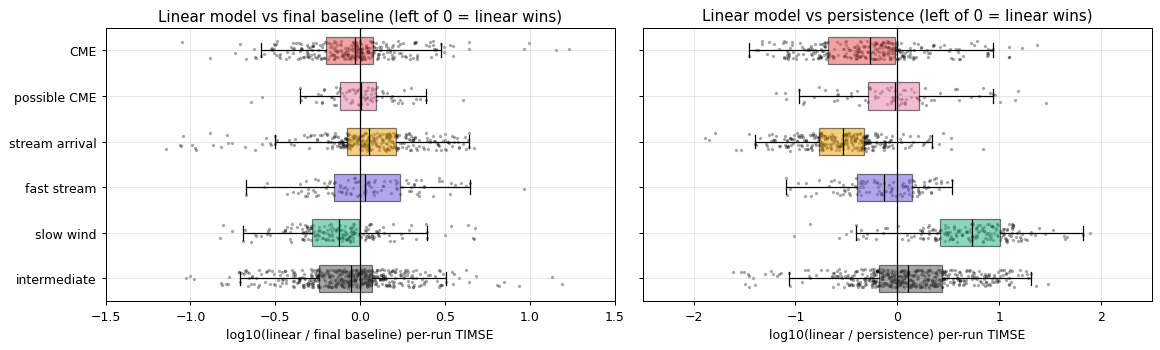

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
order = ev.REGIMES
for ax, (r, label) in zip(axes, [(vs_base, "final baseline"), (vs_pers, "persistence")],
                          strict=True):
    data = [np.log10(r[(regime == g).to_numpy()].dropna()) for g in order]
    parts = ax.boxplot(data, vert=False, showfliers=False, patch_artist=True,
                       widths=0.6, medianprops={"color": "k"})
    ax.set_yticks(range(1, len(order) + 1), order)
    for patch, g in zip(parts["boxes"], order, strict=True):
        patch.set(facecolor=REGIME_COLORS[g], alpha=0.5)
    rng = np.random.default_rng(0)
    for k, d in enumerate(data, 1):
        ax.scatter(d, k + rng.uniform(-0.2, 0.2, len(d)), s=3, color="k", alpha=0.25)
    ax.axvline(0, color="k", lw=1)
    ax.set(xlabel=f"log10(linear / {label}) per-run TIMSE",
           xlim=(-1.5, 1.5) if label == "final baseline" else (-2.5, 2.5),
           title=f"Linear model vs {label} (left of 0 = linear wins)")
axes[0].invert_yaxis()
fig.tight_layout()

## 3. Bias and level

The final baseline's main failure was a constant over-forecast of quiet wind: about 100 km/s too
high in slow and intermediate wind, growing with lead. Mean residual and RMSE by lead for each
regime (top: mean residual, negative = over-forecast; bottom: RMSE).

bias 6 h RMSE 6 h bias 24 h RMSE 24 h bias 72 h RMSE 72 h
CME            linear_model        -16     73.7     -46.5       120     -69.1       140
               final_baseline      -10       74     -42.8       122     -57.7       131
               persistence        2.19     75.5      15.3       134        45       172
possible CME   linear_model      -14.5     35.8     -55.7      80.5      -146       156
               final_baseline    -15.1     35.6     -62.7      84.6      -129       143
               persistence       -6.29     35.4     -23.5        83     -63.7       116
stream arrival linear_model      -7.06     42.8     -28.7      91.6      5.04      87.9
               final_baseline    -9.44     46.1     -49.1       103     -14.3      80.7
               persistence        9.81       46      46.3       107       144       172
fast stream    linear_model       4.18     50.5       4.3      79.6      -150       173
               final_baseline     7.82     49.3      13.4      77.6      -133       158
               persistence        9.77     52.5      20.6       101     -97.7       152
slow wind      linear_model      -19.7     27.7       -78      86.9      -152       161
               final_baseline    -24.6     31.7     -97.8       108      -166       175
               persistence        -8.6     21.1     -24.3        44     -34.1      70.3
intermediate   linear_model      -14.4     33.3     -63.9      80.9      -156       170
               final_baseline    -17.5     35.1     -74.8      90.1      -159       174
               persistence       -6.18       32     -30.9        68     -73.4       126

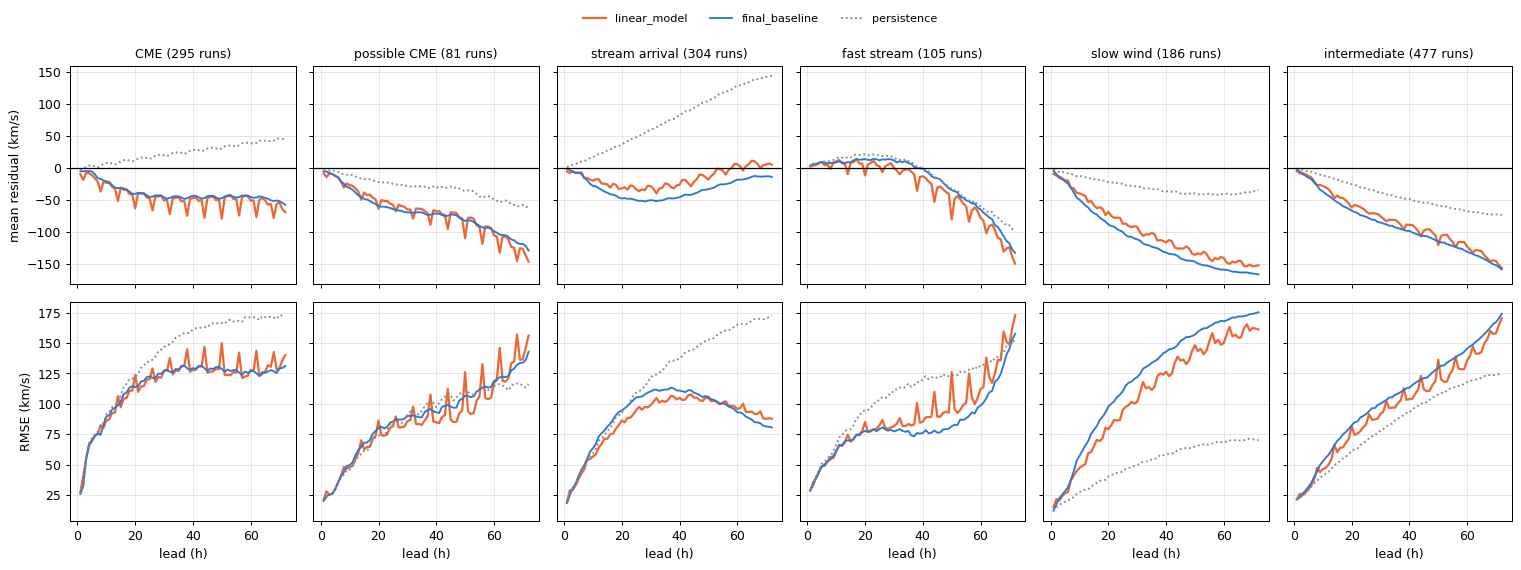

In [7]:
fig, axes = plt.subplots(2, len(ev.REGIMES), figsize=(17, 6), sharex=True, sharey="row")
bias_rows = {}
for col, g in enumerate(ev.REGIMES):
    sel = (regime == g).to_numpy()
    for m in MODELS:
        r = residuals[m][sel]
        axes[0, col].plot(lead, np.nanmean(r, axis=0), **STYLE[m])
        axes[1, col].plot(lead, np.sqrt(np.nanmean(r**2, axis=0)), **STYLE[m])
        for k in (6, 24, 72):
            bias_rows[(g, m)] = bias_rows.get((g, m), {}) | {
                f"bias {k} h": np.nanmean(r[:, k - 1]),
                f"RMSE {k} h": np.sqrt(np.nanmean(r[:, k - 1] ** 2)),
            }
    axes[0, col].axhline(0, color="k", lw=1)
    axes[0, col].set_title(f"{g} ({sel.sum()} runs)", fontsize=10)
    axes[1, col].set_xlabel("lead (h)")
axes[0, 0].set_ylabel("mean residual (km/s)")
axes[1, 0].set_ylabel("RMSE (km/s)")
fig.tight_layout()
model_legend(fig)
fmt(pd.DataFrame(bias_rows).T)

**Over-prediction in quiet wind, and the forecast floor.** For the no-CME regimes: the share of
each model's TIMSE that comes from over-prediction, and the median of (mean forecast − mean
observed) per run. Then the distribution of all forecasts at 24 h and 72 h lead against the
observed speeds (black): the final baseline almost never forecast below 450 km/s at 72 h.

share of TIMSE from over-prediction median (mean forecast - mean observed), km/s runs over-predicted on average
stream arrival linear_model                                 0.136                                         25.3                          0.655
               final_baseline                               0.273                                         39.5                          0.727
fast stream    linear_model                                 0.362                                         25.9                          0.705
               final_baseline                               0.246                                         21.5                          0.705
slow wind      linear_model                                 0.997                                         97.2                              1
               final_baseline                               0.998                                          104                              1
intermediate   linear_model                                  0.92                                         83.7                          0.985
               final_baseline                               0.918                                         86.7                          0.981

p1  p10 median  p90
24 h linear_model    370  426    503  629
     final_baseline  388  440    524  617
     observed        281  349    448  623
72 h linear_model    438  490    559  668
     final_baseline  447  502    567  655
     observed        281  349    448  623

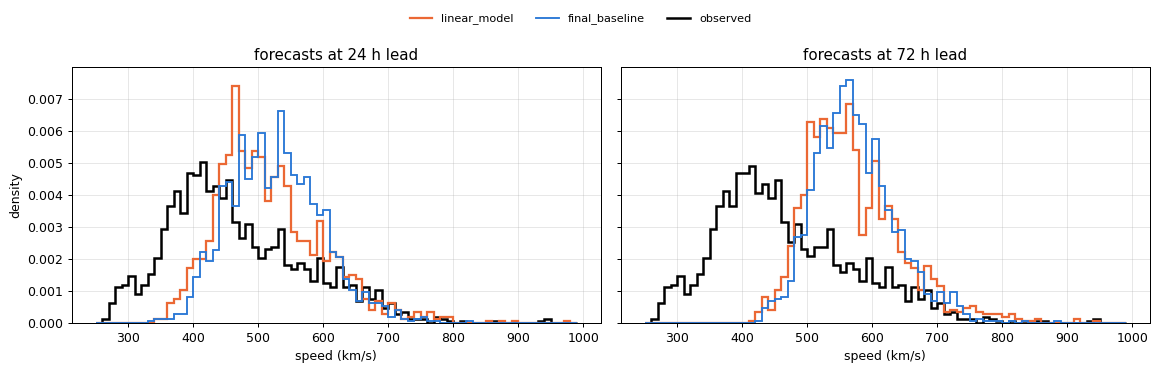

In [8]:
q = run_timse_weights(actual)
rows = {}
for g in ev.NO_CME:
    sel = (regime == g).to_numpy()
    for m in MODELS[:2]:
        e = residuals[m][sel]
        contrib = np.where(np.isfinite(e), q[sel] * e**2, 0.0)
        offset = np.nanmean(forecasts[m][sel], axis=1) - np.nanmean(actual[sel], axis=1)
        rows[(g, m)] = {
            "share of TIMSE from over-prediction": np.where(e < 0, contrib, 0).sum()
            / contrib.sum(),
            "median (mean forecast - mean observed), km/s": np.median(offset),
            "runs over-predicted on average": (offset > 0).mean(),
        }
display(fmt(pd.DataFrame(rows).T))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
bins = np.arange(250, 1000, 10)
quant = {}
for ax, k in zip(axes, (24, 72), strict=True):
    obs = actual[:, k - 1][np.isfinite(actual[:, k - 1])]
    ax.hist(obs, bins=bins, histtype="step", color="k", lw=2, density=True)
    for m in MODELS[:2]:
        ax.hist(forecasts[m][:, k - 1], bins=bins, histtype="step", density=True, **STYLE[m])
        quant[(f"{k} h", m)] = np.quantile(forecasts[m][:, k - 1], [0.01, 0.1, 0.5, 0.9])
    quant[(f"{k} h", "observed")] = np.quantile(obs, [0.01, 0.1, 0.5, 0.9])
    ax.set(title=f"forecasts at {k} h lead", xlabel="speed (km/s)")
axes[0].set_ylabel("density")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=2), "observed")], models=MODELS[:2])
fmt(pd.DataFrame(quant, index=["p1", "p10", "median", "p90"]).T)

## 4. Stream arrivals

The final baseline caught stream arrivals by already forecasting high, not by timing them. The
coronal-hole regressor is the one input that could give timing. A superposed-epoch view of the
non-CME stream arrivals: forecasts valid at each hour around the arrival (hour 0), made about 1, 2
or 3 days earlier, as the median over arrivals; black is the median observed speed.

The table gives the share of the observed rise each model reproduces: the mean over +12…+36 h
minus the mean over −36…−12 h, forecast over observed, median over arrivals.

29 non-CME stream arrivals


,linear_model: share of rise,final_baseline: share of rise,persistence: share of rise
~1 day ahead (19-30 h),0.355,0.27,0.42
~2 days ahead (43-54 h),0.116,0.0355,-0.156
~3 days ahead (61-72 h),0.0284,0.0236,-0.251


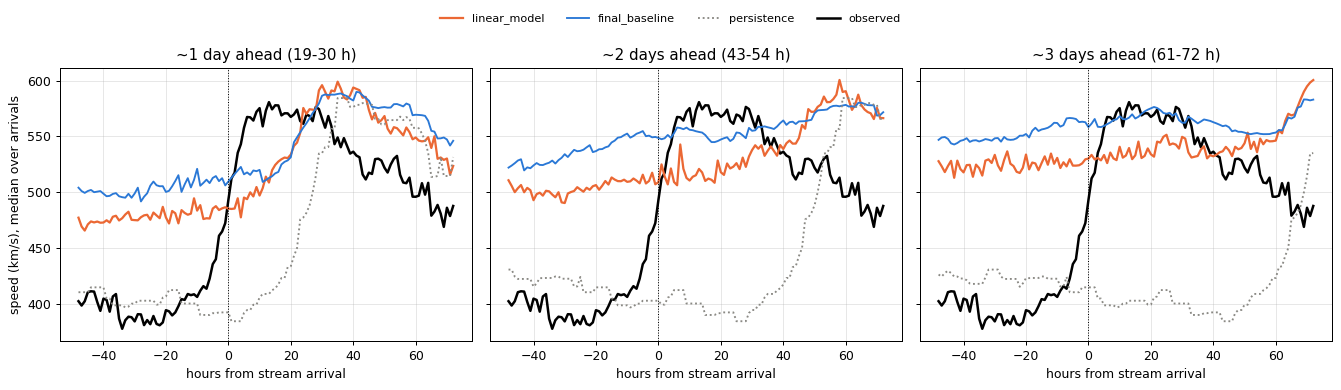

In [9]:
eval_arrivals = arrivals[(arrivals >= TRAIN_END + pd.Timedelta(days=3)) & (arrivals < EVAL_END)]
valid = t0s.values[:, None] + lead[None, :] * np.timedelta64(1, "h")
lead_grid = np.broadcast_to(lead, valid.shape)
groups = {"~1 day ahead (19-30 h)": (19, 30), "~2 days ahead (43-54 h)": (43, 54),
          "~3 days ahead (61-72 h)": (61, 72)}
rel_hours = np.arange(-48, 73)
epoch, capture = {}, {}
for gname, (lo, hi) in groups.items():
    stacks = {m: [] for m in MODELS}
    caps = {m: [] for m in MODELS}
    obs_stack = []
    for a in eval_arrivals:
        rel = (valid - a.tz_convert(None).to_datetime64()) / np.timedelta64(1, "h")
        sel = (rel >= -48) & (rel <= 72) & (lead_grid >= lo) & (lead_grid <= hi)
        obs = series.reindex(a + pd.to_timedelta(rel_hours, unit="h")).to_numpy()
        obs_stack.append(obs)
        rise_obs = np.nanmean(obs[(rel_hours >= 12) & (rel_hours <= 36)]) - np.nanmean(
            obs[(rel_hours >= -36) & (rel_hours <= -12)])
        for m in MODELS:
            df = pd.DataFrame({"rel": rel[sel].round().astype(int), "f": forecasts[m][sel]})
            curve = df.groupby("rel")["f"].mean().reindex(rel_hours)
            stacks[m].append(curve.to_numpy())
            after = curve[(curve.index >= 12) & (curve.index <= 36)].mean()
            before = curve[(curve.index >= -36) & (curve.index <= -12)].mean()
            caps[m].append((after - before) / rise_obs)
    epoch[gname] = ({m: np.nanmedian(np.array(stacks[m]), axis=0) for m in MODELS},
                    np.nanmedian(np.array(obs_stack), axis=0))
    capture[gname] = {m: np.nanmedian(caps[m]) for m in MODELS}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (gname, (curves, obs)) in zip(axes, epoch.items(), strict=True):
    ax.plot(rel_hours, obs, color="k", lw=2)
    for m in MODELS:
        ax.plot(rel_hours, curves[m], **STYLE[m])
    ax.axvline(0, color="k", lw=0.8, ls=":")
    ax.set(title=gname, xlabel="hours from stream arrival")
axes[0].set_ylabel("speed (km/s), median over arrivals")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=2), "observed")])
print(f"{len(eval_arrivals)} non-CME stream arrivals")
fmt(pd.DataFrame(capture).T.rename(columns=lambda m: f"{m}: share of rise"))

## 5. The regressors

### 5.1 Coefficients by lead

With no Box-Cox transform and the target relative to persistence, every term is in km/s: the
model forecasts `last + a_k + Σ b_kj·(speed term − mean) + Σ c_ki·z_i` plus a small smearing
constant. Left: the speed-term coefficients (km/s per km/s). Right: the regressor coefficients,
in km/s per standard deviation of the regressor (`z_i` is standardised on the training years).
The jumps at every sixth lead are a training-data artefact, explained in 5.5.

,1,6,24,48,72
last speed,-0.0251,-0.0833,-0.384,-0.532,-0.418
recurrence 27 d,0.0154,0.0529,0.199,0.195,0.147
recurrence 13.5 d,-0.00261,-0.0129,0.00195,-0.00904,0.0213
ch_cm_at_12h,-0.602,3.47,13.1,25.5,21.8
density_mean_24h,1.13,9.05,16.8,12.1,10.4
xray_peak_max_48h,1.46,6.35,14.7,12.7,12.9
b_var_mean_48h,-3.22,-2.71,-2.94,-8.28,-7.43
f107_mean_168h,-3.5,-3,-5.02,-5.2,-4.88


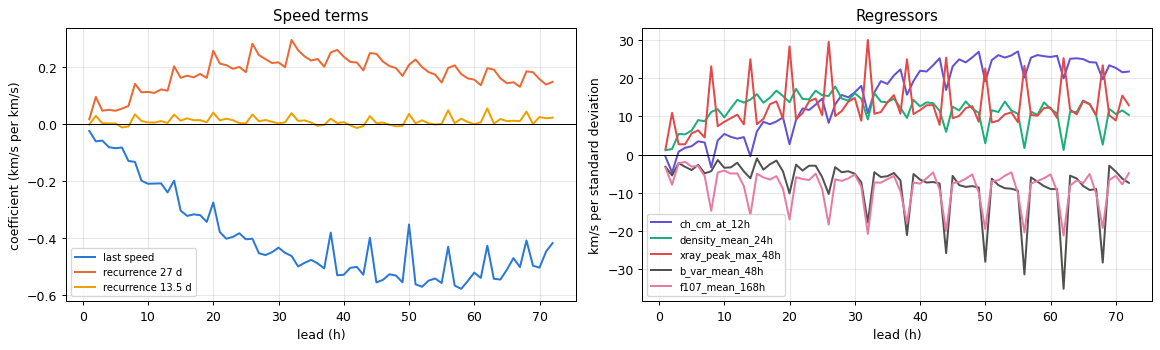

In [10]:
cfg = model.config
speed_names = ["last speed"] + [f"recurrence {d:g} d" for d in cfg.lags_days]
coef = pd.DataFrame(model.coef[:, 1:], index=lead, columns=speed_names + FEATURES)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, color in zip(speed_names, ["#2a78d6", "#eb6834", "#eda100"], strict=True):
    axes[0].plot(lead, coef[name], color=color, lw=1.6, label=name)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set(xlabel="lead (h)", ylabel="coefficient (km/s per km/s)", title="Speed terms")
axes[0].legend(fontsize=8)
feat_colors = dict(zip(FEATURES, ["#6250d6", "#1baf7a", "#e34948", "#52514e", "#e87ba4"],
                       strict=True))
for name in FEATURES:
    axes[1].plot(lead, coef[name], color=feat_colors[name], lw=1.6, label=name)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(xlabel="lead (h)", ylabel="km/s per standard deviation", title="Regressors")
axes[1].legend(fontsize=8)
fig.tight_layout()
fmt(coef.loc[[1, 6, 24, 48, 72]].T)

### 5.2 Contributions by regime

Each regressor's contribution to a forecast is `c_ki · z_i` in km/s. The table gives its mean
contribution at 24 h and 72 h lead by regime, and the spread (standard deviation over all runs).
If a regressor separates the regimes, its contribution should be negative in slow wind (pulling
the forecast down) and positive before stream arrivals.

In [11]:
z = (model.impute(x) - model.x_mean) / model.x_std
n_lead_cols = 1 + cfg.n_speed
contrib = {name: z[:, [j]] * model.coef[None, :, n_lead_cols + j]
           for j, name in enumerate(FEATURES)}
contrib["all regressors"] = sum(contrib.values())
rows = {}
for name, c in contrib.items():
    for k in (24, 72):
        row = {g: c[(regime == g).to_numpy(), k - 1].mean() for g in ev.REGIMES}
        row["std over runs"] = c[:, k - 1].std()
        rows[(name, f"{k} h")] = row
fmt(pd.DataFrame(rows).T)

CME possible CME stream arrival fast stream slow wind intermediate std over runs
ch_cm_at_12h      24 h   6.66         1.51           6.87        11.8     0.395         2.86          16.7
                  72 h   11.1         2.51           11.4        19.6     0.656         4.75          27.8
density_mean_24h  24 h  -1.92        -9.89          -3.92       -2.46     -7.49        -6.93          12.5
                  72 h  -1.19        -6.13          -2.43       -1.52     -4.65        -4.29          7.73
xray_peak_max_48h 24 h   6.18         1.24          -5.85       -7.22     -8.41        -5.51          14.9
                  72 h   5.44         1.09          -5.15       -6.35      -7.4        -4.85          13.1
b_var_mean_48h    24 h  0.334        0.456          0.155       -1.63    -0.222        -1.33          3.22
                  72 h  0.845         1.15          0.392       -4.12    -0.562        -3.37          8.13
f107_mean_168h    24 h   2.02        0.494           2.89         3.9      4.06         3.11          3.01
                  72 h   1.96        0.479           2.81        3.78      3.95         3.02          2.92
all regressors    24 h   13.3        -6.19          0.143        4.38     -11.7        -7.81          26.7
                  72 h   18.1         -0.9           7.03        11.4     -8.01        -4.75          34.9

### 5.3 Ablation

How much each regressor is worth on the eval year: the same fitted model, with one regressor
replaced by its training median for every run (the value an imputed run gets). The change is in
per-run mean and median TIMSE relative to the full model; positive means the regressor helps.
"All regressors" replaces all five, leaving the refitted speed terms; this is an analysis of the
fitted model, not a refit.

In [12]:
def scores(f):
    s = run_timse(f, actual)
    return np.nanmean(s), np.nanmedian(s), timse(actual, f)


full = scores(forecasts["linear_model"])
rows = {}
for j, name in enumerate([*FEATURES, "all regressors"]):
    xa = x.copy()
    if name == "all regressors":
        xa[:] = model.medians
    else:
        xa[:, j] = model.medians[j]
    s = scores(model.forecast(values, pos, xa))
    rows[name] = {"per-run mean, worse by": s[0] / full[0] - 1,
                  "per-run median, worse by": s[1] / full[1] - 1,
                  "pooled TIMSE, worse by": s[2] / full[2] - 1,
                  "per-run mean vs baseline": s[0] / run_scores["final_baseline"].mean()}
fmt(pd.DataFrame(rows).T)

,"per-run mean, worse by","per-run median, worse by","pooled TIMSE, worse by",per-run mean vs baseline
ch_cm_at_12h,0.113,-0.131,0.265,1.05
density_mean_24h,0.0214,0.0392,-0.0178,0.961
xray_peak_max_48h,0.0567,0.0598,0.0678,0.994
b_var_mean_48h,0.0069,0.0478,0.00186,0.947
f107_mean_168h,0.0146,-0.0661,0.0167,0.955
all regressors,0.228,-0.0735,0.339,1.16


### 5.4 The coronal-hole gap

The SDO browse archive has no AIA 193 images for about 2025-09-12 → 2025-12-16, so
`ch_cm_at_12h` is imputed (training median) for the first weeks of the eval year. Live, a missing
image is imputed the same way. Top: the regressor over the year, with the imputed runs shaded.
The table compares the linear model against the final baseline on runs with the coronal-hole
regressor observed and imputed, and splits the observed runs by quartile of coronal-hole area.

,runs,area range,linear mean,baseline mean,median linear / baseline,linear wins,"mean residual 72 h, linear","mean residual 72 h, baseline"
imputed,285,-,4.57e+06,4.4e+06,0.989,0.509,-71.7,-101
observed Q1 (small),291,0.000-0.010,8.75e+05,1.04e+06,0.758,0.735,-124,-143
observed Q2,291,0.010-0.038,1.15e+06,1.29e+06,0.909,0.605,-104,-112
observed Q3,290,0.038-0.099,1.52e+06,1.6e+06,0.98,0.521,-101,-98.5
observed Q4 (large),291,0.099-0.366,4.12e+06,4.66e+06,1.09,0.405,-112,-70


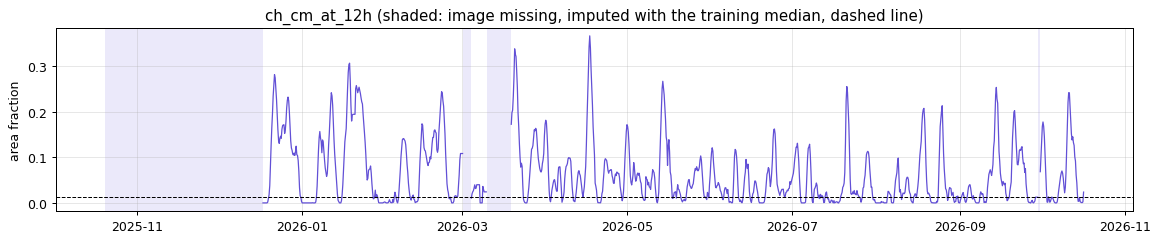

In [13]:
ch = table["ch_cm_at_12h"]
ch_missing = imputed["ch_cm_at_12h"]
fig, ax = plt.subplots(figsize=(13, 2.8))
ax.plot(ch.index, ch, color="#6250d6", lw=1)
for s, e in ev._runs(ch_missing.to_numpy()):
    ax.axvspan(t0s[s], t0s[e - 1] + pd.Timedelta(hours=6), **GAP_SPAN)
ax.axhline(model.medians[FEATURES.index("ch_cm_at_12h")], color="k", lw=0.8, ls="--")
ax.set(ylabel="area fraction", title="ch_cm_at_12h (shaded: image missing, imputed with the "
       "training median, dashed line)")
fig.tight_layout()

groups_ch = pd.Series(np.where(ch_missing, "imputed", ""), index=t0s, dtype=object)
groups_ch[~ch_missing] = pd.qcut(ch[~ch_missing], 4,
                                 labels=["observed Q1 (small)", "observed Q2", "observed Q3",
                                         "observed Q4 (large)"]).astype(str)
rows = {}
for g in ["imputed", "observed Q1 (small)", "observed Q2", "observed Q3", "observed Q4 (large)"]:
    sel = (groups_ch == g).to_numpy()
    rows[g] = {"runs": int(sel.sum()),
               "area range": f"{ch[sel].min():.3f}-{ch[sel].max():.3f}" if g != "imputed"
               else "-",
               "linear mean": run_scores.loc[sel, "linear_model"].mean(),
               "baseline mean": run_scores.loc[sel, "final_baseline"].mean(),
               "median linear / baseline": vs_base[sel].median(),
               "linear wins": (vs_base[sel] < 1).mean(),
               "mean residual 72 h, linear": np.nanmean(residuals["linear_model"][sel, 71]),
               "mean residual 72 h, baseline": np.nanmean(residuals["final_baseline"][sel, 71])}
fmt(pd.DataFrame(rows).T)

### 5.5 A training-data artefact: the six-hour sawtooth

The coefficients in 5.1, and the forecasts and residuals in sections 3 and 6, jump at every sixth
lead (8, 14, 20, … h). The final baseline doesn't. The cause is in the **training** data:
- **The glitch:** the real-time series has a one-hour glitch, 1,087 km/s at 2022-10-05 02:00 between hours of about 500 km/s.
- **Why every sixth lead:** runs start every 6 hours, so the glitch hour is the target of training runs at leads 2, 8, 14, … h.
- **Why it matters:** per-run TIMSE weights are largest for a run's fastest hours, so this one hour takes about 2% of the whole fitting weight at each of those leads, more than any other run-hour.

Left: the glitch. Middle: the largest weight any single run-hour gets at each lead (hatched: leads where it is the glitch hour). Right: one coefficient as fitted, and refitted with only that hour masked. The refit is a training-side diagnostic only; it is not scored here, so the eval year plays no part in the fix.

the glitch hour carries the largest single weight at 11 of 72 leads: [2, 8, 14, 20, 26, 32, 38, 44, 50, 62, 68]


,shipped fit,glitch masked
mean |second difference| over leads,,
last speed,0.0759,0.0214
recurrence 27 d,0.0418,0.0282
recurrence 13.5 d,0.0284,0.0108
ch_cm_at_12h,4.53,1.7
density_mean_24h,4.8,2.37
xray_peak_max_48h,12.8,2.73
b_var_mean_48h,10,1.99
f107_mean_168h,7.57,2.46


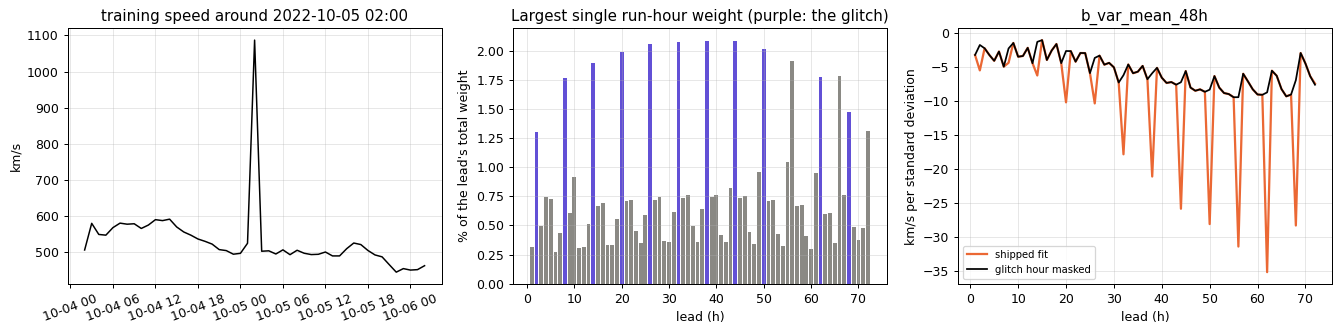

In [14]:
from training.datasets import load_train
from training.linear_model import training_runs

train = load_train()
tv = train.to_numpy(dtype=float)
train_t0s = training_runs(train)
tpos = train.index.get_indexer(train_t0s)
ty = targets(tv, tpos)
share = model.loss_weights(ty)
share = share / share.sum(axis=0)
top_run = share.argmax(axis=0)
top_hour = train_t0s[top_run] + pd.to_timedelta(lead, unit="h")
glitch = pd.Timestamp("2022-10-05T02:00Z")
is_glitch = top_hour == glitch
print(f"the glitch hour carries the largest single weight at {is_glitch.sum()} of 72 leads: "
      f"{lead[is_glitch].tolist()}")

masked = tv.copy()
masked[train.index.get_loc(glitch)] = np.nan
train_x = candidate_table(train_t0s)[FEATURES].to_numpy(dtype=float)
refit = LinearModel(model.config).fit(masked, tpos, train_x)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
w = train[glitch - pd.Timedelta(hours=24): glitch + pd.Timedelta(hours=24)]
axes[0].plot(w.index, w, color="k", lw=1.2)
axes[0].set(ylabel="km/s", title="training speed around 2022-10-05 02:00")
axes[0].tick_params(axis="x", labelrotation=20)
axes[1].bar(lead, share.max(axis=0) * 100, color=np.where(is_glitch, LOSE, "#8a8984"))
axes[1].set(xlabel="lead (h)", ylabel="% of the lead's total weight",
            title="Largest single run-hour weight (purple: the glitch)")
name = "b_var_mean_48h"
j = 1 + cfg.n_speed + FEATURES.index(name)
axes[2].plot(lead, model.coef[:, j], **STYLE["linear_model"], label="shipped fit")
axes[2].plot(lead, refit.coef[:, j], color="k", lw=1.4, label="glitch hour masked")
axes[2].set(xlabel="lead (h)", ylabel="km/s per standard deviation", title=name)
axes[2].legend(fontsize=8)
fig.tight_layout()


def roughness(c):
    return np.abs(np.diff(c, 2, axis=0)).mean(axis=0)


fmt(pd.DataFrame({"shipped fit": roughness(model.coef[:, 1:]),
                  "glitch masked": roughness(refit.coef[:, 1:])},
                 index=speed_names + FEATURES).rename_axis(
                     "mean |second difference| over leads"))

## 6. Through the year

### 6.1 Month by month

Per-run mean TIMSE by month for both models, the linear model's win share, the share of runs
with the coronal-hole regressor imputed, and each month's share of the year's change in the
per-run total (negative = a gain for the linear model; the column sums to −1).

,runs,linear mean,baseline mean,persistence mean,linear wins,ch imputed,CME runs,linear / baseline (means),share of total change
2025-10,48,1.38e+06,1.71e+06,3.46e+06,0.562,1,0,0.805,-0.072
2025-11,120,8.45e+06,8.16e+06,1.45e+07,0.45,1,0.4,1.04,0.158
2025-12,124,1.8e+06,1.53e+06,4.65e+06,0.403,0.532,0.242,1.17,0.148
2026-01,124,7.37e+06,8.6e+06,1.38e+07,0.54,0,0.25,0.856,-0.69
2026-02,112,1.17e+06,1.47e+06,3.6e+06,0.741,0,0.277,0.794,-0.152
2026-03,124,1.52e+06,1.33e+06,3.9e+06,0.605,0.387,0.355,1.14,0.103
2026-04,120,1.33e+06,1.35e+06,3e+06,0.542,0,0.125,0.986,-0.00994
2026-05,124,9.66e+05,1.29e+06,3.05e+06,0.694,0,0.129,0.751,-0.178
2026-06,120,1.28e+06,1.54e+06,4.19e+06,0.675,0,0.383,0.829,-0.143
2026-07,124,8.79e+05,9.89e+05,3.79e+06,0.492,0,0.0645,0.889,-0.0612


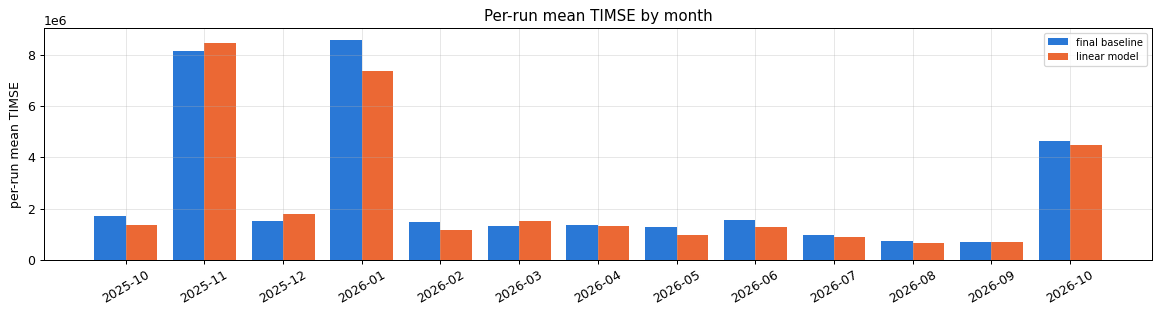

In [15]:
month = pd.Series(t0s.strftime("%Y-%m"), index=t0s)
monthly = pd.DataFrame({
    "runs": month.value_counts().sort_index(),
    "linear mean": run_scores["linear_model"].groupby(month).mean(),
    "baseline mean": run_scores["final_baseline"].groupby(month).mean(),
    "persistence mean": run_scores["persistence"].groupby(month).mean(),
    "linear wins": (vs_base < 1).groupby(month).mean(),
    "ch imputed": ch_missing.groupby(month).mean(),
    "CME runs": (regime == "CME").groupby(month).mean(),
})
monthly["linear / baseline (means)"] = monthly["linear mean"] / monthly["baseline mean"]
monthly["share of total change"] = diff.groupby(month).sum() / abs(total_change)

fig, ax = plt.subplots(figsize=(13, 3.6))
xm = np.arange(len(monthly))
ax.bar(xm - 0.2, monthly["baseline mean"], 0.4, color=STYLE["final_baseline"]["color"],
       label="final baseline")
ax.bar(xm + 0.2, monthly["linear mean"], 0.4, color=STYLE["linear_model"]["color"],
       label="linear model")
ax.set_xticks(xm, monthly.index, rotation=30)
ax.set(ylabel="per-run mean TIMSE", title="Per-run mean TIMSE by month")
ax.legend(fontsize=8)
fig.tight_layout()
fmt(monthly)

### 6.2 The year, run by run

Each pair of rows shows the observed speed (CME-affected time shaded red, possible CMEs pink,
coronal-hole regressor missing shaded purple), then the per-run ratio linear / final baseline on a
log scale at each run's `t0`: green below 1 (the linear model wins), purple above.

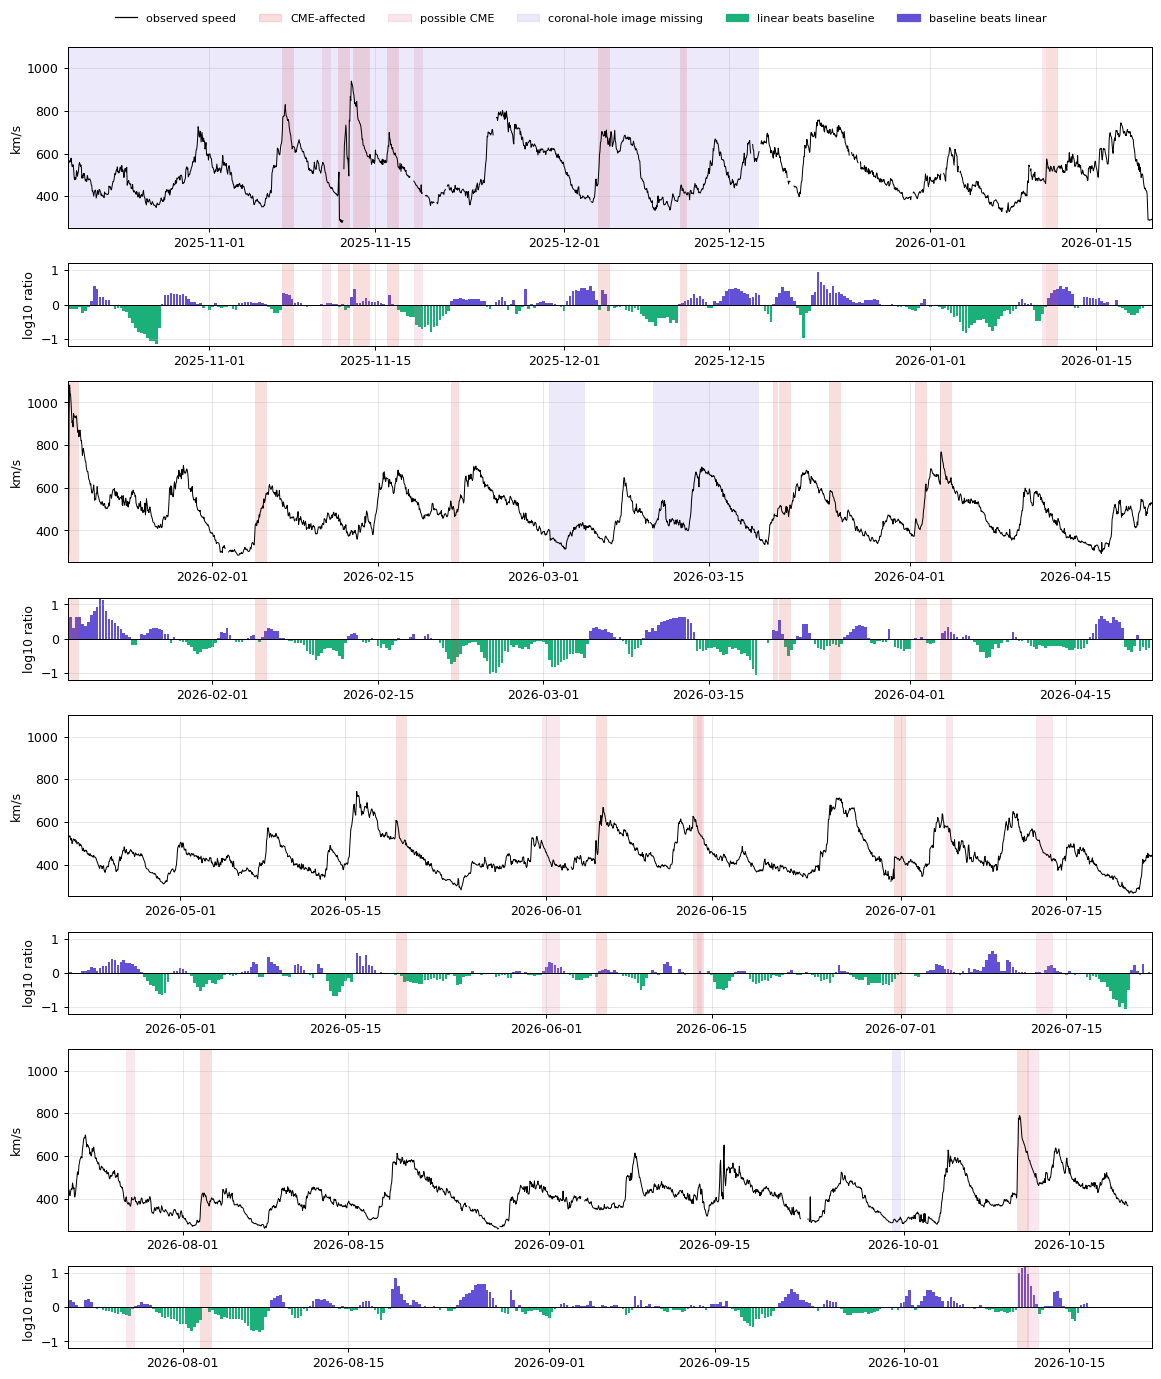

In [16]:
def shade(ax, lo, hi, gap=True):
    for mask, span in ((cme, CME_SPAN), (possible, POSSIBLE_SPAN)):
        m = mask[(mask.index >= lo) & (mask.index < hi)]
        for s, e in ev._runs(m.to_numpy()):
            ax.axvspan(m.index[s], m.index[e - 1] + pd.Timedelta(hours=1), **span)
    if gap:
        m = ch_missing[(ch_missing.index >= lo) & (ch_missing.index < hi)]
        for s, e in ev._runs(m.to_numpy()):
            ax.axvspan(m.index[s], m.index[e - 1] + pd.Timedelta(hours=6), **GAP_SPAN)


quarters = pd.date_range(TRAIN_END, EVAL_END + pd.Timedelta(days=2), periods=5)
fig, axes = plt.subplots(8, 1, figsize=(13, 15), gridspec_kw={"height_ratios": [2.2, 1] * 4})
log_ratio = np.log10(vs_base)
for k in range(4):
    lo, hi = quarters[k], quarters[k + 1]
    ax_v, ax_r = axes[2 * k], axes[2 * k + 1]
    s = series[lo:hi]
    ax_v.plot(s.index, s, color="k", lw=0.8)
    shade(ax_v, lo, hi)
    ax_v.set(ylabel="km/s", xlim=(lo, hi), ylim=(250, 1100))
    r = log_ratio[(log_ratio.index >= lo) & (log_ratio.index < hi)]
    ax_r.bar(r.index, r, width=0.22, color=np.where(r < 0, WIN, LOSE))
    ax_r.axhline(0, color="k", lw=0.8)
    shade(ax_r, lo, hi, gap=False)
    ax_r.set(ylabel="log10 ratio", xlim=(lo, hi), ylim=(-1.2, 1.2))
fig.tight_layout()
fig.legend(
    [Line2D([], [], color="k", lw=1), Patch(**{k: v for k, v in CME_SPAN.items() if k != "lw"}),
     Patch(**{k: v for k, v in POSSIBLE_SPAN.items() if k != "lw"}),
     Patch(**{k: v for k, v in GAP_SPAN.items() if k != "lw"}),
     Patch(color=WIN), Patch(color=LOSE)],
    ["observed speed", "CME-affected", "possible CME", "coronal-hole image missing",
     "linear beats baseline", "baseline beats linear"],
    loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=6, frameon=False, fontsize=9,
);

### 6.3 The worst runs

The ten runs with the highest linear-model TIMSE (they set the per-run mean and the p90), and
the ten where it loses most heavily to the final baseline.

In [17]:
cols = pd.DataFrame({
    "regime": regime,
    "linear": run_scores["linear_model"],
    "baseline": run_scores["final_baseline"],
    "persistence": run_scores["persistence"],
    "linear / baseline": vs_base,
    "peak observed": np.nanmax(actual, axis=1),
    "last speed": forecasts["persistence"][:, 0],
    "ch imputed": ch_missing,
    **{f: table[f] for f in FEATURES[:2]},
})
shown = cols.copy()
shown.index = shown.index.strftime("%Y-%m-%d %H")
print("Highest per-run TIMSE (linear model):")
display(fmt(shown.sort_values("linear", ascending=False).head(10)))
print("Largest losses to the final baseline (runs with baseline TIMSE above the median):")
big = shown[shown["baseline"] > shown["baseline"].median()]
display(fmt(big.sort_values("linear / baseline", ascending=False).head(10)))

Highest per-run TIMSE (linear model):


,regime,linear,baseline,persistence,linear / baseline,peak observed,last speed,ch imputed,ch_cm_at_12h,density_mean_24h
2026-01-19 18,CME,1.74e+08,1.89e+08,2.77e+08,0.921,1.08e+03,292,False,0.194,1.33
2026-01-19 12,CME,1.48e+08,1.56e+08,2.84e+08,0.951,1.08e+03,289,False,0.193,0.787
2025-11-12 06,CME,9.12e+07,8.77e+07,1.69e+08,1.04,940,277,True,nan,3.36
2026-01-19 06,CME,8.46e+07,9.3e+07,1.72e+08,0.911,1.08e+03,431,False,0.179,0.668
2025-11-11 18,CME,5.73e+07,5.58e+07,9.86e+07,1.03,940,410,True,nan,2.81
2025-11-11 06,CME,5.6e+07,5.05e+07,8.47e+07,1.11,940,444,True,nan,4.55
2026-01-19 00,CME,5.6e+07,7.17e+07,1.28e+08,0.781,1.08e+03,501,False,0.213,0.707
2025-11-11 00,CME,5.4e+07,4.88e+07,7.57e+07,1.11,940,469,True,nan,4.95
2025-11-11 12,CME,5.37e+07,5.26e+07,9.12e+07,1.02,940,427,True,nan,4.13
2026-01-18 18,CME,4.83e+07,6.58e+07,1.21e+08,0.733,1.08e+03,516,False,0.268,0.89


Largest losses to the final baseline (runs with baseline TIMSE above the median):


,regime,linear,baseline,persistence,linear / baseline,peak observed,last speed,ch imputed,ch_cm_at_12h,density_mean_24h
2026-04-17 06,stream arrival,4.38e+06,9.39e+05,9.82e+06,4.66,542,292,False,0.366,3.12
2026-01-20 12,CME,9.68e+06,2.2e+06,1.18e+07,4.4,901,928,False,0.194,3.95
2026-03-13 00,stream arrival,7.52e+06,1.71e+06,1.64e+07,4.39,697,420,True,nan,0.697
2026-01-20 00,CME,1.39e+07,3.16e+06,2.29e+07,4.39,996,1.04e+03,False,0.194,3.46
2026-03-12 18,stream arrival,6.62e+06,1.53e+06,1.52e+07,4.32,697,432,True,nan,0.666
2026-03-12 12,stream arrival,7.16e+06,1.7e+06,1.62e+07,4.21,697,425,True,nan,0.476
2026-01-20 18,fast stream,7.19e+06,1.71e+06,6.08e+06,4.19,871,839,False,0.25,3.54
2026-03-12 06,stream arrival,5.94e+06,1.43e+06,1.3e+07,4.17,697,449,True,nan,0.425
2026-03-12 00,stream arrival,5.89e+06,1.46e+06,1.28e+07,4.04,697,450,True,nan,0.409
2026-04-17 00,stream arrival,4.48e+06,1.17e+06,7.7e+06,3.83,542,320,False,0.341,3.06


Four examples:
- the linear model's worst run by TIMSE;
- its heaviest loss to the final baseline among stream arrivals;
- its biggest win over the final baseline in slow wind;
- its biggest win among intermediate runs.

Each panel shows the 48 h before `t0`, then the 72 h forecasts, with the observed speed in black.

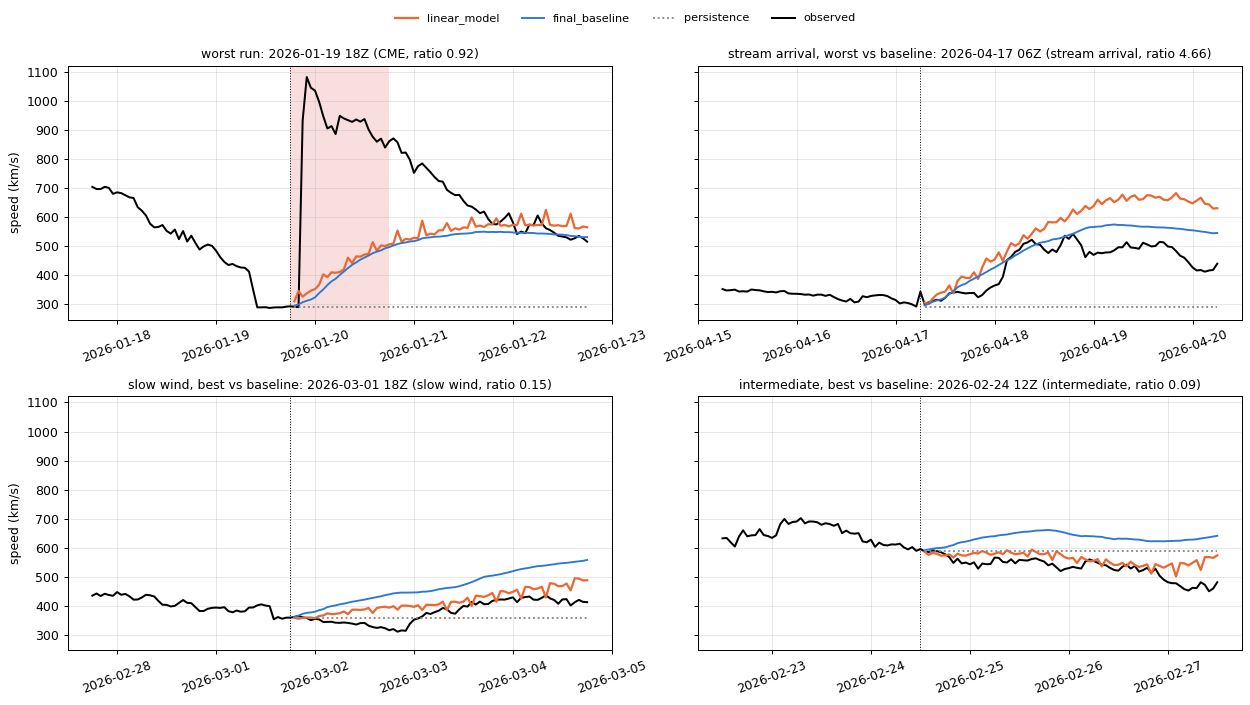

In [18]:
picks = [("worst run", cols["linear"].idxmax())]
d = cols[(regime == "stream arrival").to_numpy()]
picks.append(("stream arrival, worst vs baseline", d["linear / baseline"].idxmax()))
for g in ("slow wind", "intermediate"):
    d = cols[(regime == g).to_numpy()]
    picks.append((f"{g}, best vs baseline", d["linear / baseline"].idxmin()))

fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharey=True)
for ax, (label, t0) in zip(axes.flat, picks, strict=True):
    k = t0s.get_loc(t0)
    hist = series[t0 - pd.Timedelta(hours=48): t0 + pd.Timedelta(hours=HORIZON)]
    ax.plot(hist.index, hist, color="k", lw=1.6)
    times = t0 + pd.to_timedelta(lead, unit="h")
    for m in MODELS:
        ax.plot(times, forecasts[m][k], **STYLE[m])
    ax.axvline(t0, color="k", lw=0.8, ls=":")
    shade(ax, hist.index[0], hist.index[-1], gap=False)
    ax.set_title(f"{label}: {t0:%Y-%m-%d %H}Z ({regime.iloc[k]}, "
                 f"ratio {vs_base.iloc[k]:.2f})", fontsize=10)
    ax.tick_params(axis="x", labelrotation=20)
for ax in axes[:, 0]:
    ax.set_ylabel("speed (km/s)")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=1.6), "observed")])

## 7. Findings

Eval year 2025-10-20 → 2026-10-20, 1,448 runs.

### (i) Overall: better at almost every point of the run distribution, except around p90

| | Linear model | Final baseline | Change |
|---|---|---|---|
| Pooled TIMSE | 4.75 × 10⁷ | 5.58 × 10⁷ | −15% |
| Per-run mean | 2.44 × 10⁶ | 2.59 × 10⁶ | −6% |
| Per-run median | 7.21 × 10⁵ | 8.45 × 10⁵ | −15% |
| Per-run p90 | 4.00 × 10⁶ | 3.21 × 10⁶ | +25% |
| Runs won against the other | 56% | 44% | |
| Runs beating persistence | 57% | 53% | |

- **The per-run quantiles are 5–26% lower everywhere except p90** (section 1). The p95 is 6% lower and the p99 26% lower. The worse p90 is a band of mid-sized losses, mostly stream arrivals, not a worse tail.
- **The per-run-mean gain rests mostly on one event.**
  - The CME of 17–22 January 2026 accounts for 69% of the reduction in the per-run total (section 6.1).
  - Without those six days, the linear model is 2.5% better on the per-run mean.
  - The median and win-rate gains are spread across the year: the linear model wins more runs than it loses in 8 of 13 months (one more is a tie).

### (ii) By regime: quiet wind and CMEs gain, stream arrivals lose

| Regime | Runs | Median linear / baseline | Linear wins | Pooled linear / baseline | Share of the total change |
|---|---|---|---|---|---|
| CME | 295 | 0.93 | 59% | 0.85 | −115% |
| possible CME | 81 | 1.02 | 48% | 1.13 | −1% |
| stream arrival | 304 | 1.13 | 39% | **1.29** | **+74%** |
| fast stream | 105 | 1.07 | 49% | 1.06 | −2% |
| slow wind | 186 | **0.75** | **75%** | 0.67 | −22% |
| intermediate | 477 | 0.88 | 59% | 0.66 | −34% |

- **Quiet wind gains most relative to its size.** Pooled TIMSE is a third lower in slow and intermediate wind.
- **Quiet wind is cheap, though,** so in the per-run total those gains are outweighed by the stream-arrival losses: on the no-CME runs taken together, the per-run mean is 2% worse (1.34 × 10⁶ against 1.31 × 10⁶), even though the median run is 7% better.
- **The year's net gain comes from CME runs.** Their per-run total falls by more than the overall net change.

### (iii) The over-forecast of quiet wind is reduced at short leads only

- **At 24 h the bias falls by about a fifth:** −78 km/s in slow wind against −98 for the baseline, and −64 against −75 in intermediate wind (section 3).
- **At 72 h it is essentially unchanged:** −152 against −166 in slow wind, −156 against −159 in intermediate.
- **The forecast floor hardly moves:** at 72 h the 1st percentile is 438 km/s (baseline 447) and the median 559 (567), against an observed median of 448.
- Over-prediction is still 99.7% of the slow-wind TIMSE. The regressors pull slow-wind forecasts down by only about 8–12 km/s on average (section 5.2), far less than the bias.

### (iv) Stream arrivals: a little earlier, still mostly by level

- **Before an arrival the linear model sits lower** than the baseline (by about 25–30 km/s), so its bias in stream-arrival runs at 24 h is −29 km/s against −49 km/s (sections 3 and 4).
- **Some timing at about 2 days:** forecasts made 43–54 h ahead reproduce 12% of the observed rise, against 4% for the baseline. At 1 day it reproduces 36% (baseline 27%); at 3 days it reproduces 3% (2%).
- **It loses arrival runs anyway,** because it rises later and overshoots after the peak. Its worst losses are arrivals of a weaker stream than the coronal hole suggested (2026-04-17: the year's largest central-meridian hole, a stream peaking at 542 km/s, forecasts near 650) and arrivals with the coronal-hole image missing (2026-03-12/13).

### (v) The regressors

- **Speed terms:**
  - the last speed's weight fades to about 0.5 by 48 h, so the forecast moves half-way from persistence towards the climatology;
  - the 27-day recurrence adds 0.15–0.25;
  - the 13.5-day term is near zero.
- **The coronal-hole strip** has the largest effect at 48–72 h: +22 to +26 km/s per standard deviation. That is the 2–3-day travel time from the central meridian, as the screening suggested.
- **Flares (+13–15 km/s) and density (+10–17 km/s)** push the forecast up. Flares stand for possible CMEs, and density for the compressed region ahead of a stream. Field variability and F10.7 push it down by 3–8 km/s.
- **Ablation** (each regressor replaced by its median; section 5.3):
  - **The coronal-hole strip** carries most of the gain on the tail: without it, the per-run mean is 11% worse and pooled TIMSE 27% worse. **The median run is 13% better without it,** so it costs typical runs while saving the big ones.
  - **Flares** help everywhere (about 6% on the mean, the median and pooled TIMSE).
  - **F10.7** helps the mean slightly but costs the median 7%.
  - **All five at their medians:** the per-run mean is 16% worse than the baseline's, but the median is 7% better than the full model's. **The quiet-wind gain on typical runs comes from the refitted speed terms** (relative target, TIMSE weights). The regressors bring the gain on the per-run mean.
- **Coronal-hole size matters both ways** (section 5.4):
  - when the strip is small (lowest quartile), the linear model wins 74% of runs (median ratio 0.76);
  - when it is large (top quartile), it wins only 40% (ratio 1.09) and over-forecasts more than the baseline at 72 h (−112 against −70 km/s);
  - a large hole at the central meridian doesn't always bring a fast stream to Earth, but the model's linear term assumes it does.
- **The coronal-hole gap removes the gain.** On the 285 runs (20%) with the image missing, the model ties the baseline: median ratio 0.99, wins 51%.

### (vi) A training-data artefact: a six-hour sawtooth

- **The coefficients and forecasts jump at leads 2, 8, 14, … h** (section 5.5).
- **The cause is one glitch hour** in the training series: 1,087 km/s at 2022-10-05 02:00, between hours of about 500 km/s.
  - The run-TIMSE weights favour a run's fastest hours, so this single hour carries up to 2% of the fitting weight at 11 of the 72 leads.
  - Masking just that hour makes the coefficients 2–5× smoother.
- **The final baseline's forecasts show no sawtooth.** The size of the effect on the linear model's score hasn't been measured. The fix should be chosen and checked on the training folds, not here.

### What this means for the next model

1. **Clean isolated spikes from the training speed series** before fitting, for example by flagging hours that differ from their ±3 h median by more than a few hundred km/s, then re-run selection. This is a data fix, checked on the folds.
2. **Fill a missing coronal-hole image from an older one.** The 18 h and 24 h lags scored almost as well as 12 h on the folds (0.4968 and 0.4990 against 0.4965), so a fallback chain 12 h → 18 h → 24 h → median would recover most of the 20% of eval runs, and live runs, that lose the regressor.
3. **Make the coronal-hole effect non-linear or conditional.** Its largest values over-forecast. Candidates: a capped or log-area term, an interaction with the hole's latitude or the current speed, or a separate term for the eastern strip, which signals that a stream is still on its way.
4. **The quiet-wind level at 2–3 days is still unsolved.** The regressors say little about "no stream coming" at 72 h. That needs inputs with longer lead time (WSA-type speed predictions) or a decision on how runs are aggregated (section 4 of `final_baseline_analysis.ipynb`).
5. **Don't read too much into the per-run-mean gain.** Two-thirds of it is one CME. The median and win-rate gains, and the quiet-wind results, are the robust part.

### Caveats

- **One year, one look:** these are eval-year results, scored once after the model was fixed. The ablation and the coronal-hole split are analyses of the fitted model, not refits, and no choice was made from them.
- **Regimes:** the regime labels come from CMEs identified in the in-situ data itself (see `final_baseline_analysis.ipynb`), and they use the observed future speed, so they are a diagnostic, not an input.
- **Data:** the eval speed series has its own artefacts (e.g. the frozen 290 km/s before the January 2026 shock). Both models are scored on it, as on the live leaderboard.